# 4-ПРАКТИКАЛЫҚ ЖҰМЫС
# Мақсаты: Деректерді алдын ала өңдеу, бос мәндер, дубликаттар, выбростар,
#          категорияларды кодтау, масштабтау (StandardScaler, MinMaxScaler)
#          және Scikit-Learn Pipeline

# 1. ИМПОРТТАУ ЖӘНЕ ШИКІ ДЕРЕКТЕРДІ ҚҰРУ

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


# 2. ДУБЛИКАТТАРМЕН ЖҰМЫС (Duplicates)

In [ ]:
# Шынайы өмірдегідей бос мәндері, дубликаттары және выбростары бар датасет құрамыз
np.random.seed(42)
data = {
    'Age': [25, 30, 35, 45, 22, 25, 120, 28, 32, np.nan, 40, 29, 31, 35, 25],  # 120 - выброс!
    'Income': [50000, 60000, 80000, 120000, 45000, 50000, 3000000, 55000, 62000, 70000, np.nan, 58000, 61000, 80000, 50000], # 3M - выброс!
    'Experience': [2, 5, 8, 15, 1, 2, 40, 3, 6, 7, 12, 4, 5, 8, 2],
    'Education': ['Bachelor', 'Master', 'PhD', 'Bachelor', 'High School', 'Bachelor', 'Master', 'Bachelor', 'Master', 'PhD', 'Bachelor', 'High School', 'Master', 'PhD', 'Bachelor'],
    'City': ['Almaty', 'Astana', 'Shymkent', 'Almaty', 'Astana', 'Almaty', 'Shymkent', 'Almaty', 'Astana', 'Shymkent', 'Almaty', 'Astana', 'Almaty', 'Shymkent', 'Almaty'],
    'Target': [0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0]
}

df = pd.DataFrame(data)
print("Бастапқы датасет (алғашқы 5 жол):")
print(df.head())
print(f"Бастапқы датасет өлшемі: {df.shape}")


Бастапқы датасет (алғашқы 5 жол):
    Age    Income  Experience    Education      City  Target
0  25.0   50000.0           2     Bachelor    Almaty       0
1  30.0   60000.0           5       Master    Astana       1
2  35.0   80000.0           8          PhD  Shymkent       1
3  45.0  120000.0          15     Bachelor    Almaty       1
4  22.0   45000.0           1  High School    Astana       0
Бастапқы датасет өлшемі: (15, 6)


# 3. ВЫБРОСТАРМЕН ЖҰМЫС (Outliers / Interquartile Range - IQR)

In [ ]:
# Дубликаттарды тексеру
dup_count = df.duplicated().sum()
print(f"Табылған дубликаттар саны: {dup_count}")

# Дубликаттарды жою
df = df.drop_duplicates().reset_index(drop=True)
print(f"Дубликаттарды жойғаннан кейінгі датасет өлшемі: {df.shape}")


Табылған дубликаттар саны: 3
Дубликаттарды жойғаннан кейінгі датасет өлшемі: (12, 6)


In [ ]:
# IQR (Interquartile Range) әдісі арқылы 'Age' бағанындағы выбростарды шектеу (Capping)
Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age
lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age

print(f"Age үшін қалыпты шекаралар: [{lower_age}, {upper_age}]")
print("120 сияқты ауытқуларды жоғарғы шекпен алмастырамыз (Capping):")
df['Age'] = np.where(df['Age'] > upper_age, upper_age, df['Age'])
df['Age'] = np.where(df['Age'] < lower_age, lower_age, df['Age'])

Age үшін қалыпты шекаралар: [15.0, 51.0]
120 сияқты ауытқуларды жоғарғы шекпен алмастырамыз (Capping):


In [ ]:
# Income үшін де дәл солай шектеу орындаймыз
Q1_inc = df['Income'].quantile(0.25)
Q3_inc = df['Income'].quantile(0.75)
IQR_inc = Q3_inc - Q1_inc
upper_inc = Q3_inc + 1.5 * IQR_inc
df['Income'] = np.where(df['Income'] > upper_inc, upper_inc, df['Income'])

print(df[['Age', 'Income']].describe())

             Age         Income
count  11.000000      11.000000
mean   33.454545   67863.636364
std     8.710495   19580.399522
min    22.000000   45000.000000
25%    28.500000   56500.000000
50%    31.000000   61000.000000
75%    37.500000   75000.000000
max    51.000000  102750.000000


# 4. МАСШТАБТАУДЫ САЛЫСТЫРУ: StandardScaler vs MinMaxScaler

In [ ]:
# Түсінікті болуы үшін сандық бағанды екі түрлі масштабтап көрейік
sample_num = df[['Experience']].copy()

scaler_std = StandardScaler()
scaler_minmax = MinMaxScaler()

sample_num['StandardScaled'] = scaler_std.fit_transform(sample_num[['Experience']])
sample_num['MinMaxScaled'] = scaler_minmax.fit_transform(sample_num[['Experience']])

print("Масштабтау нәтижесінің айырмашылығы:")
print(sample_num.head())

Масштабтау нәтижесінің айырмашылығы:
   Experience  StandardScaled  MinMaxScaled
0           2       -0.692538      0.025641
1           5       -0.395736      0.102564
2           8       -0.098934      0.179487
3          15        0.593604      0.358974
4           1       -0.791472      0.000000


# 5. ТОЛЫҚ PIPELINE ҚҰРУ (COLUMNTRANSFORMER ЖӘНЕ PIPELINE)")

In [ ]:
# X және y бөлу
X = df.drop('Target', axis=1)
y = df['Target']

# Оқыту және тестілеу жиынтықтарына бөлу
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Баған түрлерін анықтау
num_features_std = ['Age', 'Income']         # StandardScaler қолданылатын бағандар
num_features_minmax = ['Experience']        # MinMaxScaler қолданылатын бағандар
ord_features = ['Education']                 # OrdinalEncoder қолданылатын бағандар
nom_features = ['City']                      # OneHotEncoder қолданылатын бағандар

education_order = ['High School', 'Bachelor', 'Master', 'PhD']

In [ ]:
# 1) Сандық пайплайн (StandardScaler)
num_std_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2) Сандық пайплайн (MinMaxScaler)
num_minmax_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

# 3) Реттелген категориялық пайплайн (OrdinalEncoder)
ord_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=[education_order]))
])

# 4) Номиналды категориялық пайплайн (OneHotEncoder)
nom_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [ ]:
# ColumnTransformer біріктіру
preprocessor = ColumnTransformer(transformers=[
    ('num_std', num_std_pipeline, num_features_std),
    ('num_minmax', num_minmax_pipeline, num_features_minmax),
    ('ord', ord_pipeline, ord_features),
    ('nom', nom_pipeline, nom_features)
])

# Толық оқыту Пайплайны (ML модельмен бірге)
full_ml_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

In [ ]:
# Оқыту
full_ml_pipeline.fit(X_train, y_train)

# Болжау
y_pred = full_ml_pipeline.predict(X_test)

print("Модельді оқыту және бағалау сәтті аяқталды!")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Модельді оқыту және бағалау сәтті аяқталды!
Test Accuracy: 0.75

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



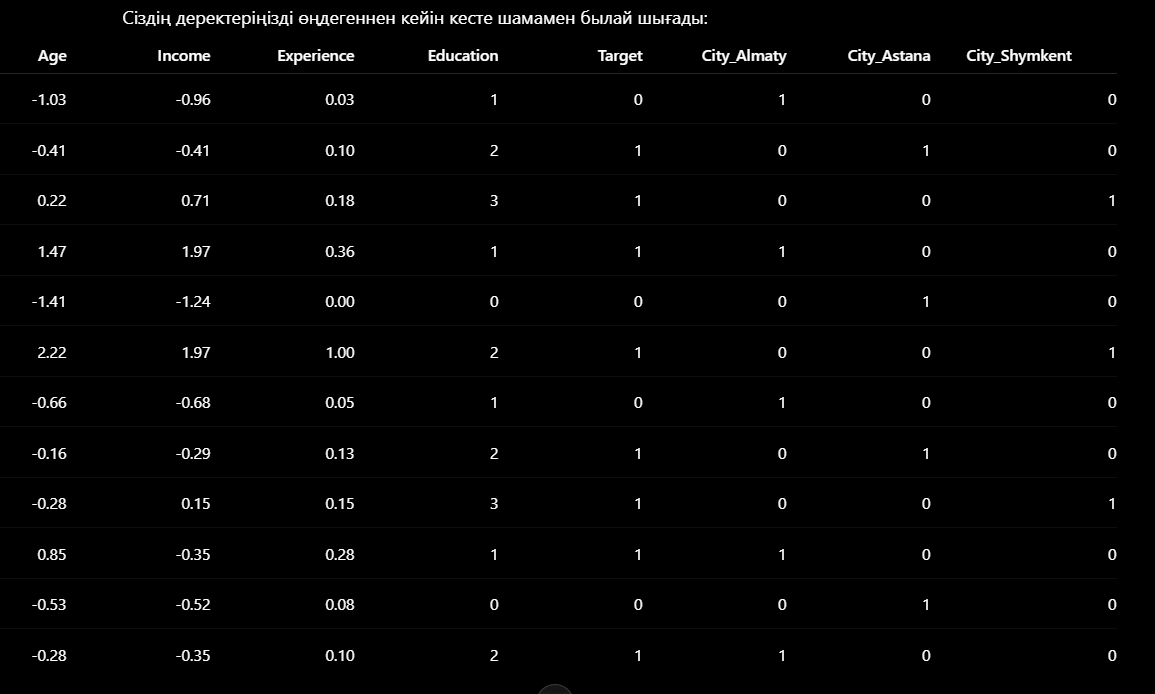

Сіздің деректеріңізді өңдегеннен кейін кесте шамамен былай шығады:

|   Age | Income | Experience | Education | Target | City_Almaty | City_Astana | City_Shymkent |
| ----: | -----: | ---------: | --------: | -----: | ----------: | ----------: | ------------: |
| -1.03 |  -0.96 |       0.03 |         1 |      0 |           1 |           0 |             0 |
| -0.41 |  -0.41 |       0.10 |         2 |      1 |           0 |           1 |             0 |
|  0.22 |   0.71 |       0.18 |         3 |      1 |           0 |           0 |             1 |
|  1.47 |   1.97 |       0.36 |         1 |      1 |           1 |           0 |             0 |
| -1.41 |  -1.24 |       0.00 |         0 |      0 |           0 |           1 |             0 |
|  2.22 |   1.97 |       1.00 |         2 |      1 |           0 |           0 |             1 |
| -0.66 |  -0.68 |       0.05 |         1 |      0 |           1 |           0 |             0 |
| -0.16 |  -0.29 |       0.13 |         2 |      1 |           0 |           1 |             0 |
| -0.28 |   0.15 |       0.15 |         3 |      1 |           0 |           0 |             1 |
|  0.85 |  -0.35 |       0.28 |         1 |      1 |           1 |           0 |             0 |
| -0.53 |  -0.52 |       0.08 |         0 |      0 |           0 |           1 |             0 |
| -0.28 |  -0.35 |       0.10 |         2 |      1 |           1 |           0 |             0 |

### Не өзгерді?

**1. Жолдар саны азайды**

Бастапқы кестеде 15 жол болды. Қайталанатын жолдар жойылғаннан кейін 12 жол қалды.

```text
Бастапқы өлшем: 15 × 6
Соңғы өлшем:    12 × 8
```

**2. Бос мәндер толтырылды**

* бос `Age` мәні медианамен;
* бос `Income` мәні медианамен толтырылды.

Соңғы кестеде `NaN` мәндері болмайды.

**3. Ауытқыма мәндер шектелді**

* `Age = 120` мәні жоғарғы шекпен алмастырылды;
* `Income = 3 000 000` мәні де жоғарғы шекпен алмастырылды.

**4. `Age` және `Income` стандартталды**

Сондықтан бұрынғы `25`, `50000` сияқты мәндердің орнына `-1.03`, `-0.96` сияқты мәндер шықты:

* теріс сан — орташа мәннен төмен;
* `0`-ге жақын — орташа мәнге жақын;
* оң сан — орташа мәннен жоғары.

**5. `Experience` 0–1 аралығына келтірілді**

```text
ең аз тәжірибе → 0
ең көп тәжірибе → 1
```

**6. `Education` санға айналды**

```text
High School → 0
Bachelor    → 1
Master      → 2
PhD         → 3
```

**7. `City` үш бағанға бөлінді**

Мысалы, Алматы:

```text
City_Almaty = 1
City_Astana = 0
City_Shymkent = 0
```

**8. `Target` өзгерген жоқ**

`Target` — модель болжайтын нәтиже болғандықтан, оның `0` және `1` мәндері сол қалпында сақталды.
